# Información del dataset

Trabajamos con anuncios de propiedades de [zameen.com](https://www.zameen.com) en cinco ciudades de Pakistán (Karachi, Lahore, Islamabad, Rawalpindi y Faisalabad). Los datos son el archivo `Property.csv` del conjunto [Zameen.com Property Data Pakistan](https://www.kaggle.com/datasets/huzzefakhan/zameencom-property-data-pakistan) de Kaggle. Se guarda en `data/bronze/` y no se sube al repositorio.

Queremos predecir el precio de venta (`price`) a partir de las características del anuncio, así que es un problema de regresión supervisada.

Empezamos con otra versión del mismo conjunto, `Entities.csv`, pero tenía un error en la superficie (se había perdido el punto decimal al convertirla) y le faltaban unos 23.000 anuncios. Por eso nos quedamos con `Property.csv`.

En este notebook solo describimos los datos tal como llegan, sin modificar nada. La limpieza está en `01_limpieza.ipynb`, y lo que dependa del análisis exploratorio lo dejamos para el EDA, que haremos solo con el train.

## 1. Carga de datos

El archivo usa `;` como separador y no trae columna de índice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/bronze/Property.csv", sep=";")
df.shape

(191393, 17)

## 2. Primer vistazo

Estos son los primeros registros. Vemos que `area` viene como texto con la unidad local (`Marla` o `Kanal`) y que `page_url` es una URL distinta en cada anuncio.

In [3]:
df.head(5)

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


## 3. Dimensiones, tipos y valores nulos

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191393 entries, 0 to 191392
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    191393 non-null  int64  
 1   location_id    191393 non-null  int64  
 2   page_url       191393 non-null  object 
 3   property_type  191393 non-null  object 
 4   price          191393 non-null  int64  
 5   location       191393 non-null  object 
 6   city           191393 non-null  object 
 7   province_name  191393 non-null  object 
 8   latitude       191393 non-null  float64
 9   longitude      191393 non-null  float64
 10  baths          191393 non-null  int64  
 11  area           191393 non-null  object 
 12  purpose        191393 non-null  object 
 13  bedrooms       191393 non-null  int64  
 14  date_added     191393 non-null  object 
 15  agency         144014 non-null  object 
 16  agent          144013 non-null  object 
dtypes: float64(2), int64(5), obje

Son 191.393 anuncios y 17 columnas. Solo `agency` y `agent` tienen nulos (47.379 y 47.380, un 24,8 %).

Dos columnas no tienen el tipo que parecen: `area` es texto (con la unidad incluida) y `date_added` también es texto, con formato mes-día-año.

## 4. Estadísticos descriptivos

In [5]:
df[["price", "latitude", "longitude", "baths", "bedrooms"]].describe()

,price,latitude,longitude,baths,bedrooms
count,1.913930e+05,191393.000000,191393.000000,191393.000000,191393.000000
mean,1.644655e+07,30.104593,71.572992,2.865956,3.171516
std,3.416412e+07,3.645941,3.080463,2.435332,1.952403
min,0.000000e+00,11.052446,25.906027,0.000000,0.000000
25%,8.000000e+04,24.972287,67.152597,0.000000,2.000000
50%,7.300000e+06,31.463563,73.077743,3.000000,3.000000
75%,1.800000e+07,33.550869,74.228218,4.000000,4.000000
max,2.000000e+09,73.184088,80.161430,403.000000,68.000000


Lo que más llama la atención:

- `price` va de 0 a 2.000 millones de rupias, y la media (16,4 millones) es mucho mayor que la mediana (7,3 millones).
- `baths` llega a 403 y `bedrooms` a 68.
- `latitude` llega a 73 y `longitude` baja a 25,9, que no son coordenadas de Pakistán.
- El 25 % de los anuncios tiene 0 baños.

## 5. Diccionario de variables

El `dtype` que muestra pandas no siempre es el tipo real de la variable, así que lo indicamos aparte. La última columna recoge lo que pensamos hacer de momento con cada variable. Es provisional y puede cambiar después del EDA.

| Variable | Descripción | Tipo real | dtype | De momento |
|---|---|---|---|---|
| `property_id` | Identificador del anuncio | Identificador | int64 | No usarla |
| `location_id` | Subzona dentro de una zona (parece una fase, sector o bloque) | Nominal, 4.321 valores | int64 | Por ver en el EDA |
| `page_url` | Enlace al anuncio | Texto | object | No usarla |
| `property_type` | Tipo de inmueble (House, Flat, Upper Portion, Lower Portion, Room, Penthouse, Farm House) | Nominal | object | Codificar |
| `price` | Precio publicado, en rupias (PKR) | Continua | int64 | Target (en euros) |
| `location` | Zona, por ejemplo «DHA Defence» | Nominal, 1.536 valores | object | Por ver en el EDA |
| `city` | Ciudad | Nominal | object | Codificar |
| `province_name` | Provincia | Nominal | object | Parece redundante con `city` |
| `latitude`, `longitude` | Coordenadas del anuncio | Continua | float64 | Resumir en la distancia al centro |
| `baths` | Número de baños | Discreta | int64 | Predictor (ver los ceros en 6.4) |
| `bedrooms` | Número de habitaciones | Discreta | int64 | Predictor (ver los ceros en 6.4) |
| `area` | Superficie con su unidad (`Marla` o `Kanal`) | Texto, pasa a continua | object | Convertir a m² |
| `purpose` | Venta o alquiler | Binaria | object | Quedarnos con las ventas |
| `date_added` | Fecha del anuncio (ver 6.7) | Fecha, guardada como texto | object | Por decidir |
| `agency`, `agent` | Agencia y agente | Nominal | object | No usarlas de momento (25 % de nulos) |

## 6. Calidad de los datos

### 6.1 Valores nulos

In [6]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
print(nulos)
print()
print("Porcentaje de nulos:")
print((nulos / len(df) * 100).round(1))

agency    47379
agent     47380
dtype: int64

Porcentaje de nulos:
agency    24.8
agent     24.8
dtype: float64


Solo hay nulos en `agency` y `agent`. De momento no las vamos a usar, así que no hace falta imputar nada.

### 6.2 Duplicados y repeticiones

In [7]:
# quitamos las columnas que identifican el anuncio
sin_ids = df.drop(columns=["property_id", "page_url", "agency", "agent"])

print("property_id repetidos:", df["property_id"].duplicated().sum())
print("page_url repetidas:", df["page_url"].duplicated().sum())

dup = sin_ids.duplicated().sum()
print("Duplicados sin las columnas de identificación:", dup, "->", round(dup / len(df) * 100, 1), "%")

# lo mismo, ignorando también la fecha
sin_fecha = sin_ids.drop(columns="date_added")
dup_fecha = sin_fecha.duplicated().sum()
print("Duplicados ignorando también la fecha:", dup_fecha, "->", round(dup_fecha / len(df) * 100, 1), "%")

property_id repetidos: 0
page_url repetidas: 0
Duplicados sin las columnas de identificación: 22758 -> 11.9 %
Duplicados ignorando también la fecha: 62265 -> 32.5 %


`property_id` y `page_url` no se repiten nunca. Pero si ignoramos las columnas de identificación, hay 22.758 anuncios (el 11,9 %) idénticos a otro. Y si además ignoramos la fecha, son 62.265 (el 32,5 %): un tercio de los anuncios coincide con otro en tipo, precio, zona, subzona, coordenadas, superficie, baños y habitaciones, y solo cambia la fecha.

Todavía no sabemos si son el mismo inmueble publicado varias veces o viviendas distintas con valores muy habituales (parcelas de 5 o 10 marla, 1 kanal, precios redondos). Importa porque, si un anuncio cae en train y otro igual en test, la evaluación podría salir demasiado optimista. Lo tendremos que mirar al hacer la partición.

### 6.3 La superficie (`area`)

La superficie viene como texto con una unidad local. Para poder estudiarla la pasamos a m² en una serie aparte, sin tocar `df`: 1 marla son 272,25 pies² y 1 kanal son 20 marla.

In [8]:
# separamos el número y la unidad: "5.6 Marla" -> 5.6 y Marla
partes = df["area"].str.split(" ", expand=True)
numero = partes[0].str.replace(",", "").astype(float)
unidad = partes[1]
print(unidad.value_counts())

# pasamos a m2 solo para poder mirarla, df no se modifica
# 1 marla = 272.25 pies2, 1 kanal = 20 marla, 1 pie2 = 0.09290304 m2
factor = unidad.map({"Marla": 1, "Kanal": 20})
m2 = numero * factor * 272.25 * 0.09290304

venta = df["purpose"] == "For Sale"

datos = pd.DataFrame({"tipo": df["property_type"], "m2": m2})
datos = datos[venta]
datos.groupby("tipo")["m2"].describe()[["count", "min", "50%", "max"]].round(0)

1
Marla    153980
Kanal     37413
Name: count, dtype: int64


,count,min,50%,max
tipo,,,,
Farm House,628.0,56.0,2985.0,210437.0
Flat,28610.0,0.0,121.0,871187.0
House,93809.0,0.0,202.0,3147544.0
Lower Portion,1010.0,18.0,134.0,303514.0
Penthouse,295.0,46.0,212.0,1012.0
Room,25.0,15.0,101.0,556.0
Upper Portion,2641.0,10.0,126.0,6070.0


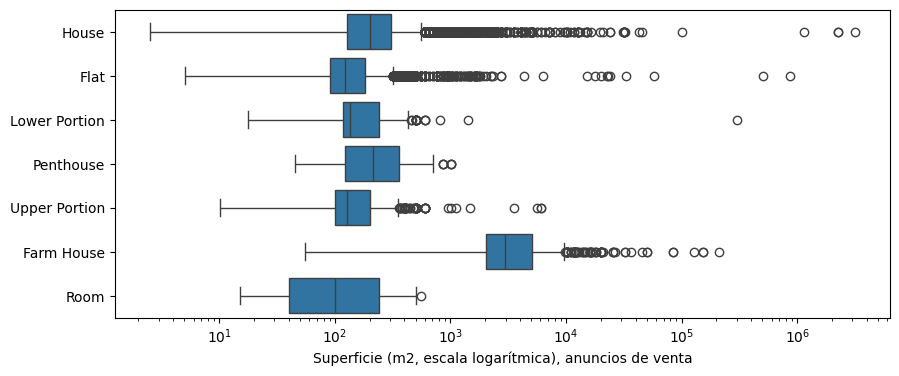

Ventas con menos de 10 m2: 17
Ventas con más de 2500 m2: 603
Pisos de más de 250 m2: 3774 de 28610 -> 13 %


In [9]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=datos[datos["m2"] > 0]["m2"], y=datos[datos["m2"] > 0]["tipo"])
plt.xscale("log")
plt.xlabel("Superficie (m2, escala logarítmica), anuncios de venta")
plt.ylabel("")
plt.show()

print("Ventas con menos de 10 m2:", (datos["m2"] < 10).sum())
print("Ventas con más de 2500 m2:", (datos["m2"] > 2500).sum())

pisos = datos[datos["tipo"] == "Flat"]
print("Pisos de más de 250 m2:", (pisos["m2"] > 250).sum(), "de", len(pisos),
      "->", round((pisos["m2"] > 250).mean() * 100), "%")

Con la conversión, la mediana sale en torno a 121 m² en los pisos, 202 m² en las casas y 2.985 m² en las granjas. También aparecen valores extremos: hay superficies de 0 m² y de hasta 3,1 millones de m². Entre los anuncios de venta, 17 miden menos de 10 m², 603 más de 2.500 m², y 3.774 pisos (el 13 %) pasan de 250 m².

En la limpieza (`01_limpieza`) fijamos los límites por tipo de vivienda a partir del precio por m²: pisos de hasta 600 m² y casas de menos de 5.000 m².

### 6.4 Ceros en baños y habitaciones

In [10]:
for col in ["price", "baths", "bedrooms"]:
    print(col, "| ceros:", (df[col] == 0).sum(),
          "| % del total:", round((df[col] == 0).mean() * 100, 1),
          "| % en ventas:", round((df[venta][col] == 0).mean() * 100, 1))

# ceros por ciudad, solo en ventas
ventas = df[venta].copy()
ventas["baths_cero"] = ventas["baths"] == 0
ventas["bedrooms_cero"] = ventas["bedrooms"] == 0
por_ciudad = ventas.groupby("city")[["baths_cero", "bedrooms_cero"]].mean() * 100
por_ciudad.round(1).sort_values("baths_cero", ascending=False)

price | ceros: 3 | % del total: 0.0 | % en ventas: 0.0
baths | ceros: 48130 | % del total: 25.1 | % en ventas: 23.6
bedrooms | ceros: 24959 | % del total: 13.0 | % en ventas: 11.2


,baths_cero,bedrooms_cero
city,,
Faisalabad,64.6,53.9
Rawalpindi,31.6,18.5
Islamabad,24.2,14.6
Karachi,21.8,9.8
Lahore,18.2,4.5


Un 25,1 % de los anuncios tiene 0 baños y un 13,0 % tiene 0 habitaciones (un 23,6 % y un 11,2 % si miramos solo las ventas). `price` tiene 3 ceros.

El porcentaje cambia mucho de una ciudad a otra. En Faisalabad el 64,6 % de las ventas tiene 0 baños y el 53,9 % tiene 0 habitaciones; en Lahore, el 18,2 % y el 4,5 %.

Un 0 puede ser un dato que no se rellenó o un valor real, y con lo que tenemos aquí no podemos saber cuál es. En la limpieza comprobamos que son datos sin rellenar y eliminamos esos anuncios. Hay que tener en cuenta que eso no afecta igual a todas las ciudades.

### 6.5 Valores imposibles o fuera de rango

In [11]:
print("Anuncios con 7 o más baños:", (df["baths"] >= 7).sum())
print("Anuncios con más de 12 baños:", (df["baths"] > 12).sum())
print("Anuncios con más de 12 habitaciones:", (df["bedrooms"] > 12).sum())
print("Máximo de baños:", df["baths"].max(), "| máximo de habitaciones:", df["bedrooms"].max())

# casas en venta con 7 a 12 baños
casas = df[venta & (df["property_type"] == "House")]
casas_grandes = casas[(casas["baths"] >= 7) & (casas["baths"] <= 12)]
print()
print("Casas en venta con 7 a 12 baños:", len(casas_grandes), "de", len(casas),
      "->", round(len(casas_grandes) / len(casas) * 100, 1), "%")
print("Superficie mediana (m2):", round(m2[casas_grandes.index].median()))
print("Precio mediano (euros, a 179.61 rupias por euro):", round(casas_grandes["price"].median() / 179.61))

# rectángulo aproximado de Pakistán
fuera = df[(df["latitude"] < 23.5) | (df["latitude"] > 37.1) |
           (df["longitude"] < 60.8) | (df["longitude"] > 77.9)]
print()
print("Anuncios con coordenadas fuera de Pakistán:", len(fuera))

Anuncios con 7 o más baños: 9965
Anuncios con más de 12 baños: 8
Anuncios con más de 12 habitaciones: 40
Máximo de baños: 403 | máximo de habitaciones: 68

Casas en venta con 7 a 12 baños: 7563 de 93809 -> 8.1 %
Superficie mediana (m2): 506
Precio mediano (euros, a 179.61 rupias por euro): 222705

Anuncios con coordenadas fuera de Pakistán: 10


Algunos valores parecen imposibles, como los 403 baños o las 68 habitaciones. Pero no todo lo alto lo es: hay 9.965 anuncios con 7 o más baños y solo 8 con más de 12 (y 40 con más de 12 habitaciones).

Entre las casas en venta, 7.563 tienen de 7 a 12 baños (el 8,1 % de las casas). Su superficie mediana es de 506 m², que son exactamente 1 kanal, y su precio mediano, de unos 222.700 €. Son valores altos, pero parecen posibles. En la limpieza nos quedamos con las viviendas de 12 baños y 12 habitaciones como máximo.

Sobre las coordenadas, 10 anuncios quedan fuera de un rectángulo aproximado que cubre Pakistán (latitud de 23,5 a 37,1 y longitud de 60,8 a 77,9). En la limpieza se descartan además los que están a más de 100 km del centro de su ciudad.

### 6.6 Variables categóricas

In [12]:
for col in ["purpose", "property_type", "city"]:
    cuenta = df[col].value_counts()
    porcentaje = (cuenta / len(df) * 100).round(1)
    print(pd.DataFrame({"anuncios": cuenta, "%": porcentaje}))
    print()

pd.crosstab(df["city"], df["province_name"])

          anuncios     %
purpose                 
For Sale    127018  66.4
For Rent     64375  33.6

               anuncios     %
property_type                
House            118915  62.1
Flat              40157  21.0
Upper Portion     18475   9.7
Lower Portion     11693   6.1
Room               1029   0.5
Farm House          725   0.4
Penthouse           399   0.2

            anuncios     %
city                      
Karachi        60484  31.6
Lahore         58736  30.7
Islamabad      40195  21.0
Rawalpindi     22898  12.0
Faisalabad      9080   4.7



province_name,Islamabad Capital,Punjab,Sindh
city,,,
Faisalabad,0,9080,0
Islamabad,40195,0,0
Karachi,0,0,60484
Lahore,0,58736,0
Rawalpindi,0,22898,0


- Las ventas son el 66,4 % de los anuncios y los alquileres el 33,6 %. Las escalas de precio son muy distintas (mediana de 13,5 millones de rupias en venta y 45.000 en alquiler), y lo que queremos predecir es el precio de venta.
- `House` es el 62 % de los anuncios. `Room`, `Farm House` y `Penthouse` son muy pocos (en torno al 0,5 % o menos cada uno).
- Cada ciudad pertenece a una sola provincia, así que `province_name` no añade nada a `city`.
- Karachi y Lahore suman el 62 % de los anuncios y Faisalabad solo el 4,7 %. Habrá que tenerlo en cuenta al dividir en train y test.

### 6.7 Ubicación y fechas

La ubicación viene en varios niveles.

In [13]:
print("Zonas distintas (location):", df["location"].nunique())
print("Subzonas distintas (location_id):", df["location_id"].nunique())
print("Máximo de subzonas dentro de una zona:", df.groupby("location")["location_id"].nunique().max())
print("Puntos de coordenadas distintos:", len(df[["latitude", "longitude"]].drop_duplicates()))

ciudades_por_zona = df.groupby("location")["city"].nunique()
print("Nombres de zona que aparecen en más de una ciudad:", (ciudades_por_zona > 1).sum())

fechas = pd.to_datetime(df["date_added"], format="%m-%d-%Y")
print()
print("Primera fecha:", fechas.min().date(), "| última fecha:", fechas.max().date())
print("Valores distintos de date_added:", fechas.nunique())
jun_jul = (fechas >= "2019-06-01") & (fechas <= "2019-07-31")
print("% de anuncios entre junio y julio de 2019:", round(jun_jul.mean() * 100, 1))

Zonas distintas (location): 1536


Subzonas distintas (location_id): 4321
Máximo de subzonas dentro de una zona: 248
Puntos de coordenadas distintos: 8818
Nombres de zona que aparecen en más de una ciudad: 66

Primera fecha: 2018-08-05 | última fecha: 2019-08-06
Valores distintos de date_added: 148
% de anuncios entre junio y julio de 2019: 72.4


Tenemos `location` (1.536 zonas), `location_id` (4.321 subzonas; una misma zona llega a tener 248) y las coordenadas, que solo toman 8.818 valores distintos para 191.393 anuncios. Con tan pocos puntos, parece que las coordenadas son las de la subzona y no las de cada vivienda.

Además, 66 nombres de zona aparecen en más de una ciudad, así que para agrupar por zona conviene usar la pareja (`city`, `location`) y no solo el nombre.

Las fechas van del 5 de agosto de 2018 al 6 de agosto de 2019, pero `date_added` solo tiene 148 valores distintos y el 72,4 % de los anuncios cae en junio y julio de 2019. Parece la fecha de la última actualización más que la de publicación, aunque con estos datos no podemos confirmarlo. Hay que tener cuidado si la usamos para ver cómo evoluciona el precio.

### 6.8 La variable objetivo (solo ventas)

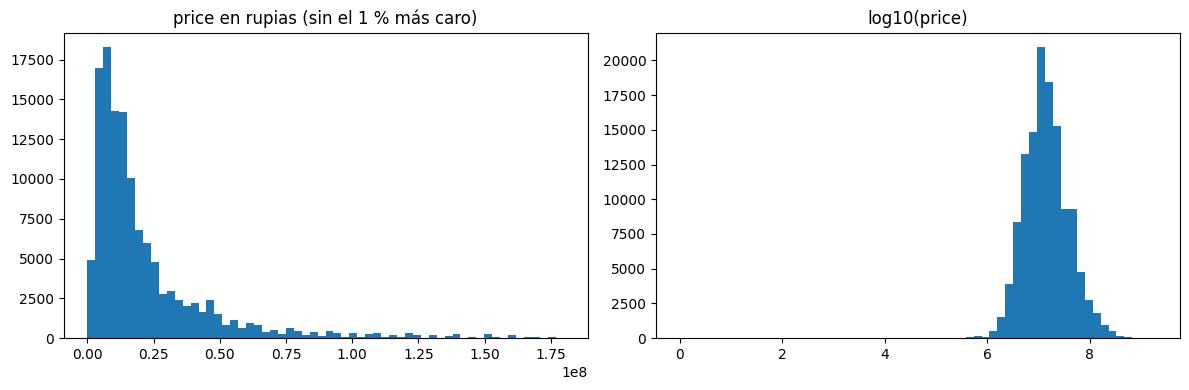

Asimetría de price: 8.72
Asimetría de log(price): -0.32
Ventas con precio menor de 1000 euros: 93


In [14]:
# solo ventas y precios mayores que 0
precio = df[venta & (df["price"] > 0)]["price"]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(precio[precio < precio.quantile(0.99)], bins=60)
plt.title("price en rupias (sin el 1 % más caro)")
plt.subplot(1, 2, 2)
plt.hist(np.log10(precio), bins=60)
plt.title("log10(price)")
plt.tight_layout()
plt.show()

print("Asimetría de price:", round(precio.skew(), 2))
print("Asimetría de log(price):", round(np.log(precio).skew(), 2))
print("Ventas con precio menor de 1000 euros:", (precio / 179.61 < 1000).sum())

El precio de venta tiene una cola muy larga a la derecha (asimetría de 8,7) y en escala logarítmica queda mucho más simétrico (asimetría de −0,3). En el EDA (`03_EDA`) confirmamos con el train que conviene modelar `log(price)`.

Hay 93 ventas por debajo de 1.000 € (unas 180.000 rupias). En la limpieza previa filtramos los precios de menos de 1.000 €.